In [1]:
from turbofan_fc_cnn_mc import fc_cnn_mc
from util.postProcess import post
from util import prelim
import numpy as np
from saveasmat_mc import saveasmat_mc
import time

In [2]:
database = '../database2/BU_supaero_10_64_66_0.07m_0.16m_conv.json'

In [3]:
# Load 2D data
rotor_test = [19, 24, 46] # Geometries to be used for testing.
rotor_drop = [] # Geometries to be removed from dataset.
input_keys = ["M_tip", "phi","th_le","th_te","x_le","x_te","radius_le","radius_te","dist_le","dist_te",
              "chord","stagger","metal_angle_le","metal_angle_te","thickness_upper_1","thickness_upper_2","thickness_upper_3",
             "thickness_upper_4","thickness_upper_5","thickness_upper_6","thickness_lower_1","thickness_lower_2",
             "thickness_lower_3","thickness_lower_4","thickness_lower_5","thickness_lower_6"] 
output_keys = ["tke", "LenScale", "vx", "vt", "p", "T", "v_mag"]
COORD_KEYS = ["x", "y", "z", "r", "th"]
RPM_test = [7000,9000,12000]
RPM_drop = [15000]

## Construct TKE training data

In [4]:
output_keys = ["tke"]
input_, output_, coordinate, label = prelim.load_data_multiChan(
    file=database,
    input_keys=input_keys,
    output_keys=output_keys,total=True,metric=True)
allSlice = prelim.find_slice_by_geom_and_slice(label,geom_values=None, rpm_values = None)
evalSlice = prelim.find_slice_by_geom_and_slice(label,geom_values=rotor_test, rpm_values = RPM_test)
dropSlice = prelim.find_slice_by_geom_and_slice(label,geom_values=rotor_test, rpm_values = RPM_drop)
allSlice = range(input_.shape[0])
trainSlice = [i for i in allSlice if i not in set(evalSlice + dropSlice)]
## Train/test spliting
reg_input_train, reg_input_test, reg_output_train, reg_output_test = prelim.regularized_train_test_mc(input_, output_, evalSlice, trainSlice=trainSlice, norm_path="normalize_parameters_tke.pkl")
label_train, coordinate_train, label_test, coordinate_test = prelim.split_coordinate_label(coordinate, label, evalSlice, trainSlice=trainSlice)

input shape      : (2890, 122)
output shape     : (2890, 64, 64, 1)
coordinate shape : (2890, 64, 64, 5)


In [5]:
len(trainSlice)

2030

## Train TKE

In [6]:
## Training multi-output model
start_time = time.perf_counter()

mc_model = fc_cnn_mc(reg_input_train,reg_output_train)
#mc_model = fc_cnn_mc(reg_input_train,reg_output_train,reg_input_test,reg_output_test)
#mc_model.build_model(print_summary = True,lr=[0.002,1000,0.985])
mc_model.build_model(print_summary = True,lr=[0.001,1000,0.983])
mc_model.fit_model(ep=3000,p=120,ts=0.1,bs=32)
mc_model.model.save('Models/test_tke.h5')

end_time = time.perf_counter()
elapsed = end_time - start_time
saveasmat_mc("Results/single_tke", mc_model.model,reg_input_train,reg_input_test,reg_output_train,reg_output_test,label_train,coordinate_train,label_test,coordinate_test,nfile='normalize_parameters_tke.pkl',output_keys=output_keys)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 256)               31488     
                                                                 
 dense_1 (Dense)             (None, 128)               32896     
                                                                 
 dense_2 (Dense)             (None, 64)                8256      
                                                                 
 reshape (Reshape)           (None, 8, 8, 1)           0         
                                                                 
 conv2d_transpose (Conv2DTra  (None, 8, 8, 256)        2560      
 nspose)                                                         
                                                                 
 leaky_re_lu (LeakyReLU)     (None, 8, 8, 256)         0         
                                                        

64/64 [==============================] - 0s 3ms/step - loss: 0.5000 - mae: 0.4405 - val_loss: 0.4955 - val_mae: 0.4408
Epoch 35/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.5484 - mae: 0.4536 - val_loss: 0.4947 - val_mae: 0.4511
Epoch 36/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.4928 - mae: 0.4401 - val_loss: 0.4957 - val_mae: 0.4396
Epoch 37/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.4872 - mae: 0.4375 - val_loss: 0.4772 - val_mae: 0.4390
Epoch 38/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.5688 - mae: 0.4587 - val_loss: 0.4969 - val_mae: 0.4413
Epoch 39/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.5464 - mae: 0.4525 - val_loss: 0.4898 - val_mae: 0.4422
Epoch 40/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.5432 - mae: 0.4551 - val_loss: 0.4918 - val_mae: 0.4388
Epoch 41/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.4808 -

Epoch 96/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0918 - mae: 0.1542 - val_loss: 0.1935 - val_mae: 0.2361
Epoch 97/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.3366 - mae: 0.2898 - val_loss: 0.1958 - val_mae: 0.2424
Epoch 98/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.3103 - mae: 0.2802 - val_loss: 0.1422 - val_mae: 0.2164
Epoch 99/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.1774 - mae: 0.2212 - val_loss: 0.1037 - val_mae: 0.1746
Epoch 100/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0952 - mae: 0.1642 - val_loss: 0.0975 - val_mae: 0.1816
Epoch 101/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.1573 - mae: 0.2080 - val_loss: 0.0742 - val_mae: 0.1512
Epoch 102/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.0924 - mae: 0.1651 - val_loss: 0.0610 - val_mae: 0.1362
Epoch 103/3000
64/64 [==============================] - 0s 4ms/ste

64/64 [==============================] - 0s 3ms/step - loss: 0.0612 - mae: 0.1367 - val_loss: 0.0419 - val_mae: 0.1101
Epoch 158/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0563 - mae: 0.1336 - val_loss: 0.0388 - val_mae: 0.1152
Epoch 159/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0470 - mae: 0.1222 - val_loss: 0.0327 - val_mae: 0.1033
Epoch 160/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.1273 - mae: 0.1758 - val_loss: 0.1174 - val_mae: 0.1831
Epoch 161/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.4064 - mae: 0.2941 - val_loss: 0.3408 - val_mae: 0.3150
Epoch 162/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.3979 - mae: 0.3209 - val_loss: 0.1301 - val_mae: 0.1974
Epoch 163/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.1804 - mae: 0.2134 - val_loss: 0.0906 - val_mae: 0.1640
Epoch 164/3000
64/64 [==============================] - 0s 3ms/step - loss: 0

64/64 [==============================] - 0s 3ms/step - loss: 0.1243 - mae: 0.1743 - val_loss: 0.1096 - val_mae: 0.2022
Epoch 219/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.0650 - mae: 0.1399 - val_loss: 0.0367 - val_mae: 0.1064
Epoch 220/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0378 - mae: 0.1079 - val_loss: 0.0289 - val_mae: 0.0908
Epoch 221/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0321 - mae: 0.0994 - val_loss: 0.0391 - val_mae: 0.0956
Epoch 222/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.1091 - mae: 0.1613 - val_loss: 0.0445 - val_mae: 0.1155
Epoch 223/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0505 - mae: 0.1233 - val_loss: 0.0298 - val_mae: 0.0946
Epoch 224/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0953 - mae: 0.1648 - val_loss: 0.0502 - val_mae: 0.1242
Epoch 225/3000
64/64 [==============================] - 0s 3ms/step - loss: 0

64/64 [==============================] - 0s 4ms/step - loss: 0.0193 - mae: 0.0827 - val_loss: 0.0167 - val_mae: 0.0792
Epoch 280/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0162 - mae: 0.0760 - val_loss: 0.0153 - val_mae: 0.0684
Epoch 281/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0268 - mae: 0.0919 - val_loss: 0.0203 - val_mae: 0.0789
Epoch 282/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0335 - mae: 0.0988 - val_loss: 0.0338 - val_mae: 0.1083
Epoch 283/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0978 - mae: 0.1425 - val_loss: 0.0347 - val_mae: 0.1010
Epoch 284/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0516 - mae: 0.1190 - val_loss: 0.0347 - val_mae: 0.1090
Epoch 285/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0424 - mae: 0.1107 - val_loss: 0.0342 - val_mae: 0.0968
Epoch 286/3000
64/64 [==============================] - 0s 3ms/step - loss: 0

... (40 outputs left out)

Epoch 2766/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0011 - mae: 0.0218 - val_loss: 0.0012 - val_mae: 0.0207
Epoch 2767/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0011 - mae: 0.0215 - val_loss: 0.0012 - val_mae: 0.0208
Epoch 2768/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0011 - mae: 0.0216 - val_loss: 0.0012 - val_mae: 0.0212
Epoch 2769/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0011 - mae: 0.0217 - val_loss: 0.0012 - val_mae: 0.0207
Epoch 2770/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0012 - mae: 0.0222 - val_loss: 0.0013 - val_mae: 0.0213
Epoch 2771/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0012 - mae: 0.0220 - val_loss: 0.0013 - val_mae: 0.0215
Epoch 2772/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0016 - mae: 0.0252 - val_loss: 0.0013 - val_mae: 0.0220
Epoch 2773/3000
64/64 [==============================] 

64/64 [==============================] - 0s 3ms/step - loss: 0.0010 - mae: 0.0211 - val_loss: 0.0011 - val_mae: 0.0203
Epoch 2827/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0011 - mae: 0.0215 - val_loss: 0.0012 - val_mae: 0.0213
Epoch 2828/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0010 - mae: 0.0211 - val_loss: 0.0011 - val_mae: 0.0202
Epoch 2829/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0010 - mae: 0.0209 - val_loss: 0.0011 - val_mae: 0.0201
Epoch 2830/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.9778e-04 - mae: 0.0208 - val_loss: 0.0011 - val_mae: 0.0201
Epoch 2831/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0010 - mae: 0.0211 - val_loss: 0.0011 - val_mae: 0.0202
Epoch 2832/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0010 - mae: 0.0208 - val_loss: 0.0011 - val_mae: 0.0200
Epoch 2833/3000
64/64 [==============================] - 0s 3ms/ste

Epoch 2886/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.8493e-04 - mae: 0.0207 - val_loss: 0.0011 - val_mae: 0.0198
Epoch 2887/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.8696e-04 - mae: 0.0207 - val_loss: 0.0011 - val_mae: 0.0202
Epoch 2888/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0010 - mae: 0.0208 - val_loss: 0.0011 - val_mae: 0.0203
Epoch 2889/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0010 - mae: 0.0210 - val_loss: 0.0011 - val_mae: 0.0200
Epoch 2890/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0010 - mae: 0.0208 - val_loss: 0.0012 - val_mae: 0.0209
Epoch 2891/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0010 - mae: 0.0211 - val_loss: 0.0011 - val_mae: 0.0204
Epoch 2892/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0010 - mae: 0.0210 - val_loss: 0.0011 - val_mae: 0.0201
Epoch 2893/3000
64/64 [========================

64/64 [==============================] - 0s 3ms/step - loss: 9.8373e-04 - mae: 0.0206 - val_loss: 0.0012 - val_mae: 0.0204
Epoch 2946/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0011 - mae: 0.0213 - val_loss: 0.0011 - val_mae: 0.0202
Epoch 2947/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0010 - mae: 0.0209 - val_loss: 0.0011 - val_mae: 0.0204
Epoch 2948/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0011 - mae: 0.0213 - val_loss: 0.0011 - val_mae: 0.0204
Epoch 2949/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.9472e-04 - mae: 0.0207 - val_loss: 0.0011 - val_mae: 0.0201
Epoch 2950/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.9508e-04 - mae: 0.0208 - val_loss: 0.0011 - val_mae: 0.0202
Epoch 2951/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.9405e-04 - mae: 0.0207 - val_loss: 0.0011 - val_mae: 0.0199
Epoch 2952/3000
64/64 [==============================] 

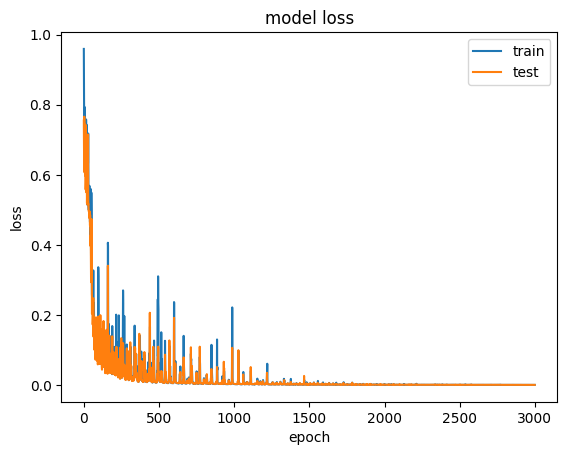

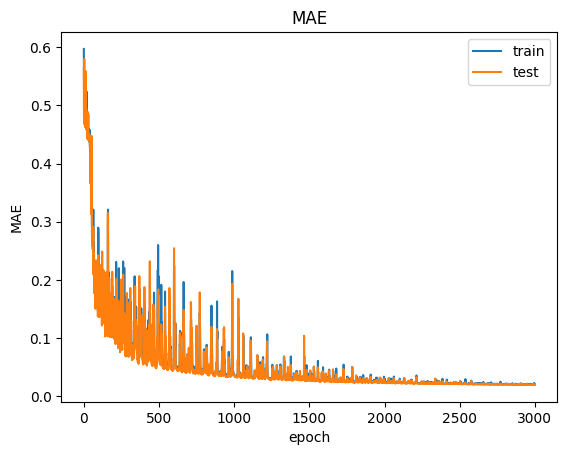

24/24 [==============================] - 0s 923us/step
mean mae on test data:  [0.10043349944562682]
R-squared on test data:  [0.8798665858433897]
24/24 [==============================] - 0s 925us/step
mean mae on test data:  [0.06258113025111264]
R-squared on test data:  [0.899114899681623]


([0.06258113025111264], [0.899114899681623])

In [7]:
mc_model.plot_loss()
post(mc_model.model,reg_input_test,reg_output_test).pixelError_mc()
post(mc_model.model,reg_input_test,reg_output_test).circError_mc()

## Construct vx training data

In [8]:
output_keys = ["vx"]
input_, output_, coordinate, label = prelim.load_data_multiChan(
    file=database,
    input_keys=input_keys,
    output_keys=output_keys,total=True,metric=True)
evalSlice = prelim.find_slice_by_geom_and_slice(label,geom_values=rotor_test, rpm_values = RPM_test)
dropSlice = prelim.find_slice_by_geom_and_slice(label,geom_values=rotor_test, rpm_values = RPM_drop)
allSlice = range(input_.shape[0])
trainSlice = [i for i in allSlice if i not in set(evalSlice + dropSlice)]
## Train/test spliting
reg_input_train, reg_input_test, reg_output_train, reg_output_test = prelim.regularized_train_test_mc(input_, output_, evalSlice, trainSlice=trainSlice, norm_path="normalize_parameters_vx.pkl")
label_train, coordinate_train, label_test, coordinate_test = prelim.split_coordinate_label(coordinate, label, evalSlice, trainSlice=trainSlice)

input shape      : (2890, 122)
output shape     : (2890, 64, 64, 1)
coordinate shape : (2890, 64, 64, 5)


## Train vx

In [9]:
## Training multi-output model
start_time = time.perf_counter()

mc_model = fc_cnn_mc(reg_input_train,reg_output_train)
#mc_model = fc_cnn_mc(reg_input_train,reg_output_train,reg_input_test,reg_output_test)
#mc_model.build_model(print_summary = True,lr=[0.002,1000,0.985])
mc_model.build_model(print_summary = True,lr=[0.001,1000,0.983])
mc_model.fit_model(ep=3000,p=120,ts=0.1,bs=32)
mc_model.model.save('Models/vx.h5')

end_time = time.perf_counter()
elapsed = end_time - start_time
saveasmat_mc("Results/single_vx", mc_model.model,reg_input_train,reg_input_test,reg_output_train,reg_output_test,label_train,coordinate_train,label_test,coordinate_test,nfile='normalize_parameters_vx.pkl',output_keys=output_keys)

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 256)               31488     
                                                                 
 dense_4 (Dense)             (None, 128)               32896     
                                                                 
 dense_5 (Dense)             (None, 64)                8256      
                                                                 
 reshape_1 (Reshape)         (None, 8, 8, 1)           0         
                                                                 
 conv2d_transpose_9 (Conv2DT  (None, 8, 8, 256)        2560      
 ranspose)                                                       
                                                                 
 leaky_re_lu_8 (LeakyReLU)   (None, 8, 8, 256)         0         
                                                      

64/64 [==============================] - 0s 3ms/step - loss: 0.0289 - mae: 0.1172 - val_loss: 0.0302 - val_mae: 0.1147
Epoch 35/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0297 - mae: 0.1191 - val_loss: 0.0354 - val_mae: 0.1359
Epoch 36/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0304 - mae: 0.1218 - val_loss: 0.0336 - val_mae: 0.1267
Epoch 37/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0326 - mae: 0.1265 - val_loss: 0.0305 - val_mae: 0.1168
Epoch 38/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0288 - mae: 0.1173 - val_loss: 0.0304 - val_mae: 0.1198
Epoch 39/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0293 - mae: 0.1191 - val_loss: 0.0308 - val_mae: 0.1184
Epoch 40/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0313 - mae: 0.1246 - val_loss: 0.0336 - val_mae: 0.1360
Epoch 41/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0393 -

Epoch 96/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0173 - mae: 0.0920 - val_loss: 0.0174 - val_mae: 0.0923
Epoch 97/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0179 - mae: 0.0927 - val_loss: 0.0189 - val_mae: 0.0961
Epoch 98/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0250 - mae: 0.1129 - val_loss: 0.0326 - val_mae: 0.1352
Epoch 99/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0206 - mae: 0.1027 - val_loss: 0.0177 - val_mae: 0.0869
Epoch 100/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0176 - mae: 0.0939 - val_loss: 0.0199 - val_mae: 0.1006
Epoch 101/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0155 - mae: 0.0870 - val_loss: 0.0154 - val_mae: 0.0828
Epoch 102/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0161 - mae: 0.0882 - val_loss: 0.0215 - val_mae: 0.1009
Epoch 103/3000
64/64 [==============================] - 0s 3ms/ste

64/64 [==============================] - 0s 3ms/step - loss: 0.0062 - mae: 0.0553 - val_loss: 0.0073 - val_mae: 0.0545
Epoch 158/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0119 - mae: 0.0779 - val_loss: 0.0182 - val_mae: 0.0962
Epoch 159/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0115 - mae: 0.0771 - val_loss: 0.0079 - val_mae: 0.0574
Epoch 160/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0062 - mae: 0.0538 - val_loss: 0.0088 - val_mae: 0.0602
Epoch 161/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0083 - mae: 0.0630 - val_loss: 0.0076 - val_mae: 0.0559
Epoch 162/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0063 - mae: 0.0553 - val_loss: 0.0076 - val_mae: 0.0584
Epoch 163/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0071 - mae: 0.0591 - val_loss: 0.0067 - val_mae: 0.0517
Epoch 164/3000
64/64 [==============================] - 0s 3ms/step - loss: 0

64/64 [==============================] - 0s 3ms/step - loss: 0.0041 - mae: 0.0431 - val_loss: 0.0045 - val_mae: 0.0395
Epoch 219/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0036 - mae: 0.0398 - val_loss: 0.0046 - val_mae: 0.0453
Epoch 220/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0078 - mae: 0.0584 - val_loss: 0.0272 - val_mae: 0.1087
Epoch 221/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0114 - mae: 0.0738 - val_loss: 0.0061 - val_mae: 0.0514
Epoch 222/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0044 - mae: 0.0441 - val_loss: 0.0055 - val_mae: 0.0452
Epoch 223/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0043 - mae: 0.0434 - val_loss: 0.0045 - val_mae: 0.0411
Epoch 224/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0051 - mae: 0.0478 - val_loss: 0.0044 - val_mae: 0.0426
Epoch 225/3000
64/64 [==============================] - 0s 3ms/step - loss: 0

64/64 [==============================] - 0s 3ms/step - loss: 0.0032 - mae: 0.0398 - val_loss: 0.0039 - val_mae: 0.0391
Epoch 280/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0050 - mae: 0.0479 - val_loss: 0.0045 - val_mae: 0.0460
Epoch 281/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.0054 - mae: 0.0534 - val_loss: 0.0061 - val_mae: 0.0522
Epoch 282/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.0040 - mae: 0.0440 - val_loss: 0.0055 - val_mae: 0.0514
Epoch 283/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0040 - mae: 0.0442 - val_loss: 0.0037 - val_mae: 0.0377
Epoch 284/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0024 - mae: 0.0331 - val_loss: 0.0027 - val_mae: 0.0310
Epoch 285/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0022 - mae: 0.0326 - val_loss: 0.0030 - val_mae: 0.0343
Epoch 286/3000
64/64 [==============================] - 0s 3ms/step - loss: 0

... (43 outputs left out)

64/64 [==============================] - 0s 3ms/step - loss: 9.9595e-05 - mae: 0.0073 - val_loss: 1.0693e-04 - val_mae: 0.0075
Epoch 2824/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.0104e-04 - mae: 0.0074 - val_loss: 1.0778e-04 - val_mae: 0.0076
Epoch 2825/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.8960e-05 - mae: 0.0073 - val_loss: 1.0478e-04 - val_mae: 0.0074
Epoch 2826/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.8209e-05 - mae: 0.0073 - val_loss: 1.0288e-04 - val_mae: 0.0073
Epoch 2827/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.9800e-05 - mae: 0.0074 - val_loss: 1.1159e-04 - val_mae: 0.0077
Epoch 2828/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.0111e-04 - mae: 0.0074 - val_loss: 1.0424e-04 - val_mae: 0.0074
Epoch 2829/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.9510e-05 - mae: 0.0073 - val_loss: 1.0382e-04 - val_mae: 0.0074
Epoch 2830/3000

64/64 [==============================] - 0s 3ms/step - loss: 1.0487e-04 - mae: 0.0075 - val_loss: 1.0489e-04 - val_mae: 0.0074
Epoch 2881/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.8928e-05 - mae: 0.0073 - val_loss: 1.0742e-04 - val_mae: 0.0076
Epoch 2882/3000
64/64 [==============================] - 0s 4ms/step - loss: 9.8371e-05 - mae: 0.0073 - val_loss: 1.0194e-04 - val_mae: 0.0073
Epoch 2883/3000
64/64 [==============================] - 0s 4ms/step - loss: 9.7952e-05 - mae: 0.0073 - val_loss: 1.0336e-04 - val_mae: 0.0074
Epoch 2884/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.6278e-05 - mae: 0.0072 - val_loss: 1.0140e-04 - val_mae: 0.0073
Epoch 2885/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.7844e-05 - mae: 0.0073 - val_loss: 1.0466e-04 - val_mae: 0.0074
Epoch 2886/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.7222e-05 - mae: 0.0073 - val_loss: 1.0237e-04 - val_mae: 0.0073
Epoch 2887/3000

64/64 [==============================] - 0s 3ms/step - loss: 9.7202e-05 - mae: 0.0072 - val_loss: 1.0374e-04 - val_mae: 0.0074
Epoch 2938/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.0028e-04 - mae: 0.0073 - val_loss: 1.0358e-04 - val_mae: 0.0074
Epoch 2939/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.7460e-05 - mae: 0.0073 - val_loss: 1.0163e-04 - val_mae: 0.0073
Epoch 2940/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.6929e-05 - mae: 0.0072 - val_loss: 1.0354e-04 - val_mae: 0.0074
Epoch 2941/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.6427e-05 - mae: 0.0072 - val_loss: 1.0326e-04 - val_mae: 0.0074
Epoch 2942/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.7258e-05 - mae: 0.0073 - val_loss: 1.0522e-04 - val_mae: 0.0075
Epoch 2943/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.3030e-04 - mae: 0.0085 - val_loss: 1.3953e-04 - val_mae: 0.0087
Epoch 2944/3000

64/64 [==============================] - 0s 3ms/step - loss: 9.6466e-05 - mae: 0.0072 - val_loss: 1.0237e-04 - val_mae: 0.0074
Epoch 2995/3000
64/64 [==============================] - 0s 4ms/step - loss: 9.5958e-05 - mae: 0.0072 - val_loss: 1.0245e-04 - val_mae: 0.0074
Epoch 2996/3000
64/64 [==============================] - 0s 3ms/step - loss: 9.9488e-05 - mae: 0.0074 - val_loss: 1.0299e-04 - val_mae: 0.0074
Epoch 2997/3000
64/64 [==============================] - 0s 4ms/step - loss: 9.8694e-05 - mae: 0.0073 - val_loss: 1.1109e-04 - val_mae: 0.0077
Epoch 2998/3000
64/64 [==============================] - 0s 4ms/step - loss: 9.9535e-05 - mae: 0.0074 - val_loss: 1.0556e-04 - val_mae: 0.0074
Epoch 2999/3000
64/64 [==============================] - 0s 4ms/step - loss: 9.8406e-05 - mae: 0.0073 - val_loss: 1.0672e-04 - val_mae: 0.0076
Epoch 3000/3000
24/24 [==============================] - 0s 1ms/step


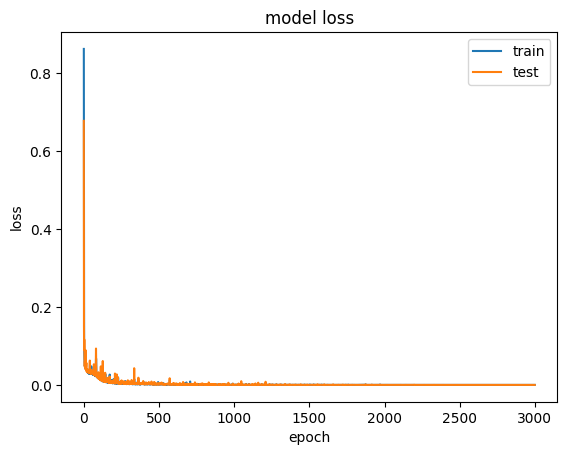

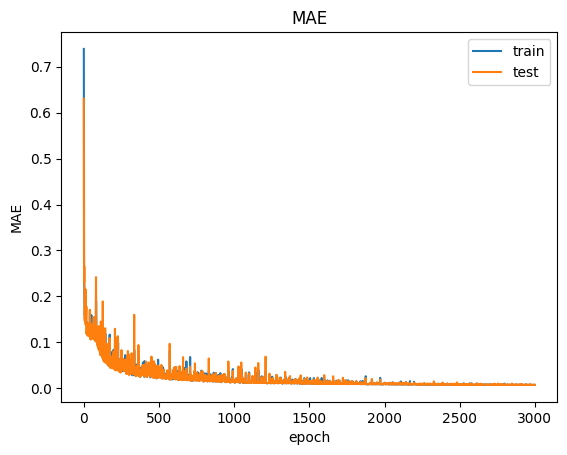

24/24 [==============================] - 0s 1ms/step
mean mae on test data:  [0.06579966831283184]
R-squared on test data:  [0.9842312503779398]
24/24 [==============================] - 0s 1ms/step
mean mae on test data:  [0.04612997864945481]
R-squared on test data:  [0.9912890265833276]


([0.04612997864945481], [0.9912890265833276])

In [10]:
mc_model.plot_loss()
post(mc_model.model,reg_input_test,reg_output_test).pixelError_mc()
post(mc_model.model,reg_input_test,reg_output_test).circError_mc()

## Construct vt training data

In [11]:
output_keys = ["vt"]
input_, output_, coordinate, label = prelim.load_data_multiChan(
    file=database,
    input_keys=input_keys,
    output_keys=output_keys,total=True,metric=True)
evalSlice = prelim.find_slice_by_geom_and_slice(label,geom_values=rotor_test, rpm_values = RPM_test)
dropSlice = prelim.find_slice_by_geom_and_slice(label,geom_values=rotor_test, rpm_values = RPM_drop)
allSlice = range(input_.shape[0])
trainSlice = [i for i in allSlice if i not in set(evalSlice + dropSlice)]
## Train/test spliting
reg_input_train, reg_input_test, reg_output_train, reg_output_test = prelim.regularized_train_test_mc(input_, output_, evalSlice, trainSlice=trainSlice, norm_path="normalize_parameters_vt.pkl")
label_train, coordinate_train, label_test, coordinate_test = prelim.split_coordinate_label(coordinate, label, evalSlice, trainSlice=trainSlice)

input shape      : (2890, 122)
output shape     : (2890, 64, 64, 1)
coordinate shape : (2890, 64, 64, 5)


## Train vt

In [12]:
## Training multi-output model
start_time = time.perf_counter()

mc_model = fc_cnn_mc(reg_input_train,reg_output_train)
#mc_model = fc_cnn_mc(reg_input_train,reg_output_train,reg_input_test,reg_output_test)
#mc_model.build_model(print_summary = True,lr=[0.002,1000,0.985])
mc_model.build_model(print_summary = True,lr=[0.001,1000,0.983])
mc_model.fit_model(ep=3000,p=120,ts=0.1,bs=32)
mc_model.model.save('Models/vt.h5')

end_time = time.perf_counter()
elapsed = end_time - start_time
saveasmat_mc("Results/single_vt", mc_model.model,reg_input_train,reg_input_test,reg_output_train,reg_output_test,label_train,coordinate_train,label_test,coordinate_test,nfile='normalize_parameters_vt.pkl',output_keys=output_keys)

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_6 (Dense)             (None, 256)               31488     
                                                                 
 dense_7 (Dense)             (None, 128)               32896     
                                                                 
 dense_8 (Dense)             (None, 64)                8256      
                                                                 
 reshape_2 (Reshape)         (None, 8, 8, 1)           0         
                                                                 
 conv2d_transpose_18 (Conv2D  (None, 8, 8, 256)        2560      
 Transpose)                                                      
                                                                 
 leaky_re_lu_16 (LeakyReLU)  (None, 8, 8, 256)         0         
                                                      

64/64 [==============================] - 0s 3ms/step - loss: 0.0359 - mae: 0.1289 - val_loss: 0.0425 - val_mae: 0.1526
Epoch 35/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0353 - mae: 0.1286 - val_loss: 0.0359 - val_mae: 0.1281
Epoch 36/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0316 - mae: 0.1194 - val_loss: 0.0330 - val_mae: 0.1212
Epoch 37/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0327 - mae: 0.1213 - val_loss: 0.0339 - val_mae: 0.1225
Epoch 38/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0318 - mae: 0.1203 - val_loss: 0.0324 - val_mae: 0.1175
Epoch 39/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0305 - mae: 0.1158 - val_loss: 0.0319 - val_mae: 0.1167
Epoch 40/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.0318 - mae: 0.1194 - val_loss: 0.0370 - val_mae: 0.1322
Epoch 41/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0346 -

Epoch 96/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0258 - mae: 0.1068 - val_loss: 0.0273 - val_mae: 0.1115
Epoch 97/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0269 - mae: 0.1103 - val_loss: 0.0346 - val_mae: 0.1247
Epoch 98/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0296 - mae: 0.1179 - val_loss: 0.0281 - val_mae: 0.1125
Epoch 99/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0262 - mae: 0.1090 - val_loss: 0.0262 - val_mae: 0.1054
Epoch 100/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.0273 - mae: 0.1114 - val_loss: 0.0310 - val_mae: 0.1272
Epoch 101/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.0256 - mae: 0.1077 - val_loss: 0.0264 - val_mae: 0.1084
Epoch 102/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0265 - mae: 0.1103 - val_loss: 0.0280 - val_mae: 0.1080
Epoch 103/3000
64/64 [==============================] - 0s 3ms/ste

64/64 [==============================] - 0s 4ms/step - loss: 0.0126 - mae: 0.0756 - val_loss: 0.0164 - val_mae: 0.0923
Epoch 158/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0159 - mae: 0.0867 - val_loss: 0.0175 - val_mae: 0.0941
Epoch 159/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0142 - mae: 0.0814 - val_loss: 0.0139 - val_mae: 0.0805
Epoch 160/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0129 - mae: 0.0765 - val_loss: 0.0120 - val_mae: 0.0741
Epoch 161/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0141 - mae: 0.0814 - val_loss: 0.0124 - val_mae: 0.0751
Epoch 162/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.0134 - mae: 0.0793 - val_loss: 0.0160 - val_mae: 0.0882
Epoch 163/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.0150 - mae: 0.0846 - val_loss: 0.0130 - val_mae: 0.0765
Epoch 164/3000
64/64 [==============================] - 0s 4ms/step - loss: 0

64/64 [==============================] - 0s 3ms/step - loss: 0.0086 - mae: 0.0636 - val_loss: 0.0097 - val_mae: 0.0658
Epoch 219/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0094 - mae: 0.0653 - val_loss: 0.0085 - val_mae: 0.0612
Epoch 220/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0086 - mae: 0.0630 - val_loss: 0.0100 - val_mae: 0.0671
Epoch 221/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.0091 - mae: 0.0651 - val_loss: 0.0107 - val_mae: 0.0705
Epoch 222/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.0103 - mae: 0.0689 - val_loss: 0.0110 - val_mae: 0.0698
Epoch 223/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0096 - mae: 0.0670 - val_loss: 0.0071 - val_mae: 0.0577
Epoch 224/3000
64/64 [==============================] - 0s 4ms/step - loss: 0.0070 - mae: 0.0560 - val_loss: 0.0061 - val_mae: 0.0533
Epoch 225/3000
64/64 [==============================] - 0s 4ms/step - loss: 0

64/64 [==============================] - 0s 3ms/step - loss: 0.0089 - mae: 0.0645 - val_loss: 0.0065 - val_mae: 0.0553
Epoch 280/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0059 - mae: 0.0515 - val_loss: 0.0053 - val_mae: 0.0493
Epoch 281/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0063 - mae: 0.0522 - val_loss: 0.0102 - val_mae: 0.0669
Epoch 282/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0065 - mae: 0.0540 - val_loss: 0.0068 - val_mae: 0.0588
Epoch 283/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0055 - mae: 0.0507 - val_loss: 0.0045 - val_mae: 0.0451
Epoch 284/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0054 - mae: 0.0500 - val_loss: 0.0048 - val_mae: 0.0481
Epoch 285/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0069 - mae: 0.0577 - val_loss: 0.0100 - val_mae: 0.0713
Epoch 286/3000
64/64 [==============================] - 0s 3ms/step - loss: 0

... (42 outputs left out)

64/64 [==============================] - 0s 3ms/step - loss: 2.2040e-04 - mae: 0.0108 - val_loss: 2.0077e-04 - val_mae: 0.0104
Epoch 2778/3000
64/64 [==============================] - 0s 3ms/step - loss: 2.0011e-04 - mae: 0.0103 - val_loss: 1.9777e-04 - val_mae: 0.0102
Epoch 2779/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9662e-04 - mae: 0.0102 - val_loss: 2.0163e-04 - val_mae: 0.0104
Epoch 2780/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9453e-04 - mae: 0.0102 - val_loss: 1.9303e-04 - val_mae: 0.0101
Epoch 2781/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9856e-04 - mae: 0.0103 - val_loss: 1.9989e-04 - val_mae: 0.0103
Epoch 2782/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9588e-04 - mae: 0.0102 - val_loss: 1.9430e-04 - val_mae: 0.0102
Epoch 2783/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9526e-04 - mae: 0.0102 - val_loss: 1.9447e-04 - val_mae: 0.0102
Epoch 2784/3000

64/64 [==============================] - 0s 3ms/step - loss: 1.9405e-04 - mae: 0.0102 - val_loss: 1.9336e-04 - val_mae: 0.0101
Epoch 2835/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9188e-04 - mae: 0.0101 - val_loss: 1.9189e-04 - val_mae: 0.0101
Epoch 2836/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9322e-04 - mae: 0.0101 - val_loss: 1.9367e-04 - val_mae: 0.0101
Epoch 2837/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9381e-04 - mae: 0.0101 - val_loss: 1.9412e-04 - val_mae: 0.0102
Epoch 2838/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9313e-04 - mae: 0.0101 - val_loss: 1.9317e-04 - val_mae: 0.0101
Epoch 2839/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9414e-04 - mae: 0.0102 - val_loss: 1.9462e-04 - val_mae: 0.0102
Epoch 2840/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9292e-04 - mae: 0.0101 - val_loss: 1.9189e-04 - val_mae: 0.0101
Epoch 2841/3000

64/64 [==============================] - 0s 3ms/step - loss: 1.8989e-04 - mae: 0.0100 - val_loss: 1.9167e-04 - val_mae: 0.0101
Epoch 2892/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.8948e-04 - mae: 0.0100 - val_loss: 1.8877e-04 - val_mae: 0.0100
Epoch 2893/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.8858e-04 - mae: 0.0100 - val_loss: 1.9025e-04 - val_mae: 0.0101
Epoch 2894/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.8968e-04 - mae: 0.0100 - val_loss: 1.9164e-04 - val_mae: 0.0101
Epoch 2895/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9418e-04 - mae: 0.0102 - val_loss: 1.9144e-04 - val_mae: 0.0101
Epoch 2896/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9253e-04 - mae: 0.0101 - val_loss: 1.9127e-04 - val_mae: 0.0101
Epoch 2897/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9332e-04 - mae: 0.0101 - val_loss: 1.9278e-04 - val_mae: 0.0101
Epoch 2898/3000

64/64 [==============================] - 0s 3ms/step - loss: 1.8728e-04 - mae: 0.0100 - val_loss: 1.8706e-04 - val_mae: 0.0100
Epoch 2949/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.8728e-04 - mae: 0.0100 - val_loss: 1.8958e-04 - val_mae: 0.0101
Epoch 2950/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9586e-04 - mae: 0.0102 - val_loss: 2.0076e-04 - val_mae: 0.0104
Epoch 2951/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9160e-04 - mae: 0.0101 - val_loss: 1.8837e-04 - val_mae: 0.0100
Epoch 2952/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9008e-04 - mae: 0.0101 - val_loss: 1.9661e-04 - val_mae: 0.0103
Epoch 2953/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9576e-04 - mae: 0.0102 - val_loss: 1.9398e-04 - val_mae: 0.0102
Epoch 2954/3000
64/64 [==============================] - 0s 3ms/step - loss: 1.9129e-04 - mae: 0.0101 - val_loss: 1.8995e-04 - val_mae: 0.0101
Epoch 2955/3000

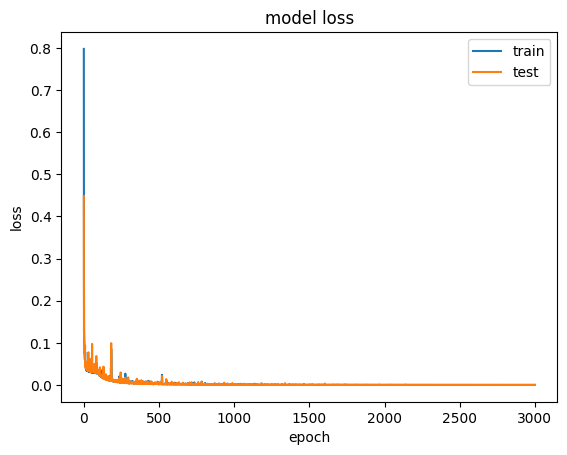

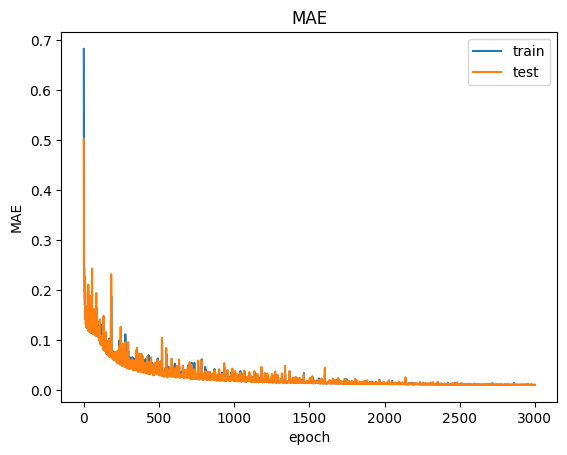

24/24 [==============================] - 0s 918us/step
mean mae on test data:  [0.08790513514002632]
R-squared on test data:  [0.9808664569052417]
24/24 [==============================] - 0s 908us/step
mean mae on test data:  [0.05920928817161716]
R-squared on test data:  [0.991689403691178]


([0.05920928817161716], [0.991689403691178])

In [13]:
mc_model.plot_loss()
post(mc_model.model,reg_input_test,reg_output_test).pixelError_mc()
post(mc_model.model,reg_input_test,reg_output_test).circError_mc()

## Construct Lambda training data

In [14]:
output_keys = ["LenScale"]
input_, output_, coordinate, label = prelim.load_data_multiChan(
    file=database,
    input_keys=input_keys,
    output_keys=output_keys,total=True,metric=True)
evalSlice = prelim.find_slice_by_geom_and_slice(label,geom_values=rotor_test, rpm_values = RPM_test)
dropSlice = prelim.find_slice_by_geom_and_slice(label,geom_values=rotor_test, rpm_values = RPM_drop)
allSlice = range(input_.shape[0])
trainSlice = [i for i in allSlice if i not in set(evalSlice + dropSlice)]
## Train/test spliting
reg_input_train, reg_input_test, reg_output_train, reg_output_test = prelim.regularized_train_test_mc(input_, output_, evalSlice, trainSlice=trainSlice, norm_path="normalize_parameters_ls.pkl")
label_train, coordinate_train, label_test, coordinate_test = prelim.split_coordinate_label(coordinate, label, evalSlice, trainSlice=trainSlice)

input shape      : (2890, 122)
output shape     : (2890, 64, 64, 1)
coordinate shape : (2890, 64, 64, 5)


## Train Lambda

In [15]:
## Training multi-output model
start_time = time.perf_counter()

mc_model = fc_cnn_mc(reg_input_train,reg_output_train)
#mc_model = fc_cnn_mc(reg_input_train,reg_output_train,reg_input_test,reg_output_test)
#mc_model.build_model(print_summary = True,lr=[0.002,1000,0.985])
mc_model.build_model(print_summary = True,lr=[0.001,1000,0.983])
mc_model.fit_model(ep=3000,p=120,ts=0.1,bs=32)
mc_model.model.save('Models/ls.h5')

end_time = time.perf_counter()
elapsed = end_time - start_time
saveasmat_mc("Results/single_ls", mc_model.model,reg_input_train,reg_input_test,reg_output_train,reg_output_test,label_train,coordinate_train,label_test,coordinate_test,nfile='normalize_parameters_ls.pkl',output_keys=output_keys)

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_9 (Dense)             (None, 256)               31488     
                                                                 
 dense_10 (Dense)            (None, 128)               32896     
                                                                 
 dense_11 (Dense)            (None, 64)                8256      
                                                                 
 reshape_3 (Reshape)         (None, 8, 8, 1)           0         
                                                                 
 conv2d_transpose_27 (Conv2D  (None, 8, 8, 256)        2560      
 Transpose)                                                      
                                                                 
 leaky_re_lu_24 (LeakyReLU)  (None, 8, 8, 256)         0         
                                                      

64/64 [==============================] - 0s 3ms/step - loss: 0.0553 - mae: 0.1606 - val_loss: 0.0727 - val_mae: 0.1944
Epoch 35/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0708 - mae: 0.1865 - val_loss: 0.0414 - val_mae: 0.1447
Epoch 36/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0377 - mae: 0.1378 - val_loss: 0.0416 - val_mae: 0.1439
Epoch 37/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0409 - mae: 0.1420 - val_loss: 0.0303 - val_mae: 0.1208
Epoch 38/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0340 - mae: 0.1301 - val_loss: 0.0312 - val_mae: 0.1220
Epoch 39/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0359 - mae: 0.1318 - val_loss: 0.0491 - val_mae: 0.1511
Epoch 40/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0380 - mae: 0.1363 - val_loss: 0.0393 - val_mae: 0.1393
Epoch 41/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0295 -

Epoch 96/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0159 - mae: 0.0886 - val_loss: 0.0139 - val_mae: 0.0840
Epoch 97/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0173 - mae: 0.0921 - val_loss: 0.0276 - val_mae: 0.1053
Epoch 98/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0306 - mae: 0.1211 - val_loss: 0.0202 - val_mae: 0.1020
Epoch 99/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0142 - mae: 0.0842 - val_loss: 0.0107 - val_mae: 0.0736
Epoch 100/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0124 - mae: 0.0790 - val_loss: 0.0134 - val_mae: 0.0825
Epoch 101/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0153 - mae: 0.0874 - val_loss: 0.0125 - val_mae: 0.0797
Epoch 102/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0136 - mae: 0.0821 - val_loss: 0.0156 - val_mae: 0.0876
Epoch 103/3000
64/64 [==============================] - 0s 3ms/ste

64/64 [==============================] - 0s 3ms/step - loss: 0.0104 - mae: 0.0728 - val_loss: 0.0086 - val_mae: 0.0662
Epoch 158/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0097 - mae: 0.0707 - val_loss: 0.0109 - val_mae: 0.0739
Epoch 159/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0103 - mae: 0.0730 - val_loss: 0.0162 - val_mae: 0.0885
Epoch 160/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0108 - mae: 0.0738 - val_loss: 0.0076 - val_mae: 0.0625
Epoch 161/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0077 - mae: 0.0636 - val_loss: 0.0077 - val_mae: 0.0633
Epoch 162/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0091 - mae: 0.0683 - val_loss: 0.0105 - val_mae: 0.0768
Epoch 163/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0224 - mae: 0.1021 - val_loss: 0.0375 - val_mae: 0.1349
Epoch 164/3000
64/64 [==============================] - 0s 3ms/step - loss: 0

64/64 [==============================] - 0s 3ms/step - loss: 0.0064 - mae: 0.0580 - val_loss: 0.0068 - val_mae: 0.0599
Epoch 219/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0068 - mae: 0.0592 - val_loss: 0.0088 - val_mae: 0.0661
Epoch 220/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0063 - mae: 0.0566 - val_loss: 0.0099 - val_mae: 0.0697
Epoch 221/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0075 - mae: 0.0616 - val_loss: 0.0060 - val_mae: 0.0565
Epoch 222/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0069 - mae: 0.0590 - val_loss: 0.0106 - val_mae: 0.0715
Epoch 223/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0085 - mae: 0.0652 - val_loss: 0.0063 - val_mae: 0.0583
Epoch 224/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0070 - mae: 0.0595 - val_loss: 0.0088 - val_mae: 0.0670
Epoch 225/3000
64/64 [==============================] - 0s 3ms/step - loss: 0

64/64 [==============================] - 0s 3ms/step - loss: 0.0073 - mae: 0.0604 - val_loss: 0.0072 - val_mae: 0.0575
Epoch 280/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0070 - mae: 0.0589 - val_loss: 0.0090 - val_mae: 0.0665
Epoch 281/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0151 - mae: 0.0854 - val_loss: 0.0148 - val_mae: 0.0804
Epoch 282/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0101 - mae: 0.0693 - val_loss: 0.0064 - val_mae: 0.0582
Epoch 283/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0061 - mae: 0.0562 - val_loss: 0.0050 - val_mae: 0.0508
Epoch 284/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0044 - mae: 0.0481 - val_loss: 0.0036 - val_mae: 0.0438
Epoch 285/3000
64/64 [==============================] - 0s 3ms/step - loss: 0.0038 - mae: 0.0448 - val_loss: 0.0038 - val_mae: 0.0454
Epoch 286/3000
64/64 [==============================] - 0s 3ms/step - loss: 0

... (19 outputs left out)

64/64 [==============================] - 0s 3ms/step - loss: 6.2754e-04 - mae: 0.0184 - val_loss: 5.9440e-04 - val_mae: 0.0181
Epoch 1471/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.4436e-04 - mae: 0.0171 - val_loss: 5.0316e-04 - val_mae: 0.0166
Epoch 1472/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.2658e-04 - mae: 0.0168 - val_loss: 5.8953e-04 - val_mae: 0.0179
Epoch 1473/3000
64/64 [==============================] - 0s 3ms/step - loss: 6.0049e-04 - mae: 0.0179 - val_loss: 6.3879e-04 - val_mae: 0.0187
Epoch 1474/3000
64/64 [==============================] - 0s 3ms/step - loss: 6.2762e-04 - mae: 0.0185 - val_loss: 6.8405e-04 - val_mae: 0.0195
Epoch 1475/3000
64/64 [==============================] - 0s 3ms/step - loss: 6.0758e-04 - mae: 0.0181 - val_loss: 5.6740e-04 - val_mae: 0.0177
Epoch 1476/3000
64/64 [==============================] - 0s 3ms/step - loss: 6.4328e-04 - mae: 0.0187 - val_loss: 8.6443e-04 - val_mae: 0.0215
Epoch 1477/3000

64/64 [==============================] - 0s 3ms/step - loss: 5.1267e-04 - mae: 0.0166 - val_loss: 6.1100e-04 - val_mae: 0.0185
Epoch 1528/3000
64/64 [==============================] - 0s 3ms/step - loss: 6.6941e-04 - mae: 0.0190 - val_loss: 7.1067e-04 - val_mae: 0.0200
Epoch 1529/3000
64/64 [==============================] - 0s 3ms/step - loss: 6.1988e-04 - mae: 0.0183 - val_loss: 6.2729e-04 - val_mae: 0.0186
Epoch 1530/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.7744e-04 - mae: 0.0176 - val_loss: 6.1082e-04 - val_mae: 0.0183
Epoch 1531/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.7691e-04 - mae: 0.0177 - val_loss: 7.0252e-04 - val_mae: 0.0197
Epoch 1532/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.8235e-04 - mae: 0.0177 - val_loss: 5.7291e-04 - val_mae: 0.0176
Epoch 1533/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.7477e-04 - mae: 0.0176 - val_loss: 5.3296e-04 - val_mae: 0.0171
Epoch 1534/3000

64/64 [==============================] - 0s 3ms/step - loss: 6.9841e-04 - mae: 0.0192 - val_loss: 6.9142e-04 - val_mae: 0.0192
Epoch 1585/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.8127e-04 - mae: 0.0177 - val_loss: 5.4355e-04 - val_mae: 0.0174
Epoch 1586/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.4549e-04 - mae: 0.0171 - val_loss: 5.2279e-04 - val_mae: 0.0169
Epoch 1587/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.2030e-04 - mae: 0.0167 - val_loss: 5.0823e-04 - val_mae: 0.0166
Epoch 1588/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.1580e-04 - mae: 0.0167 - val_loss: 5.1747e-04 - val_mae: 0.0170
Epoch 1589/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.2054e-04 - mae: 0.0168 - val_loss: 4.9730e-04 - val_mae: 0.0166
Epoch 1590/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.2219e-04 - mae: 0.0168 - val_loss: 5.0716e-04 - val_mae: 0.0167
Epoch 1591/3000

64/64 [==============================] - 0s 3ms/step - loss: 5.1103e-04 - mae: 0.0166 - val_loss: 5.1467e-04 - val_mae: 0.0168
Epoch 1642/3000
64/64 [==============================] - 0s 3ms/step - loss: 5.2859e-04 - mae: 0.0169 - val_loss: 4.9972e-04 - val_mae: 0.0167
Epoch 1643/3000
64/64 [==============================] - 0s 3ms/step - loss: 4.9610e-04 - mae: 0.0164 - val_loss: 4.7964e-04 - val_mae: 0.0163
Epoch 1644/3000
64/64 [==============================] - 0s 3ms/step - loss: 4.7960e-04 - mae: 0.0161 - val_loss: 4.7792e-04 - val_mae: 0.0162
Epoch 1645/3000
64/64 [==============================] - 0s 3ms/step - loss: 4.9498e-04 - mae: 0.0164 - val_loss: 4.7037e-04 - val_mae: 0.0161
Epoch 1646/3000
64/64 [==============================] - 0s 3ms/step - loss: 4.7167e-04 - mae: 0.0160 - val_loss: 5.7027e-04 - val_mae: 0.0176
Epoch 1647/3000
64/64 [==============================] - 0s 3ms/step - loss: 4.9987e-04 - mae: 0.0165 - val_loss: 5.6310e-04 - val_mae: 0.0178
Epoch 1648/3000

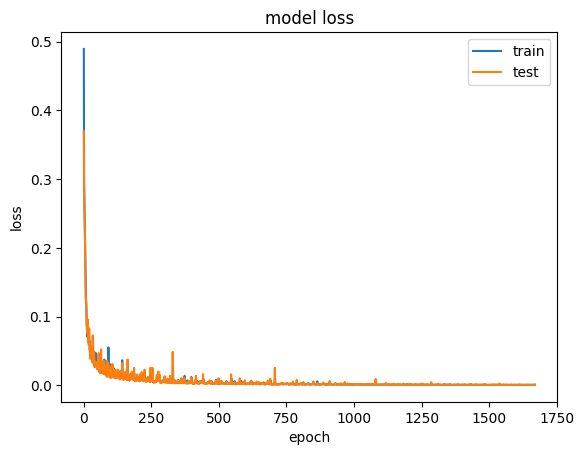

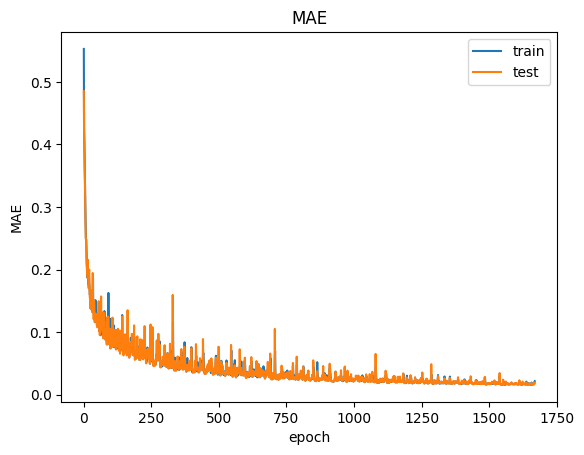

24/24 [==============================] - 0s 913us/step
mean mae on test data:  [0.11433475328626547]
R-squared on test data:  [0.9442317292329275]
24/24 [==============================] - 0s 906us/step
mean mae on test data:  [0.07658056481935213]
R-squared on test data:  [0.9646107199125971]


([0.07658056481935213], [0.9646107199125971])

In [16]:
mc_model.plot_loss()
post(mc_model.model,reg_input_test,reg_output_test).pixelError_mc()
post(mc_model.model,reg_input_test,reg_output_test).circError_mc()